# 03 — Calculus and Gradient Descent

**Overview:** derivative → partial derivative → gradient → chain rule, via manual numerical
approximation, then a from-scratch gradient descent on a quadratic function and a small MSE loss.

**Required libraries:** `numpy`, `matplotlib`.

Connects to: `02_probability_statistics.ipynb` (expected-loss gradients). Leads directly to Day
3's `16_backpropagation`, which is this same chain rule applied repeatedly through a network.

## 0. Environment

In [1]:
import numpy as np
import matplotlib.pyplot as plt
print("numpy:", np.__version__)
rng = np.random.default_rng(42)


numpy: 2.5.3


## 1. The derivative

**Equation:** `f'(x) = lim_{h->0} [f(x+h) - f(x)] / h`

💡 **Intuition:** "if I nudge `x` by a tiny amount, how much does `f(x)` move, per unit of
nudge?" We approximate this numerically (finite differences) before trusting any analytic
formula.

In [2]:
def f(x):
    return x**2

def numerical_derivative(f, x, h=1e-5):
    return (f(x + h) - f(x - h)) / (2 * h)   # central difference: more accurate than one-sided

analytic_derivative = lambda x: 2 * x   # d/dx x^2 = 2x

for x0 in [-2.0, 0.0, 3.0]:
    numeric = numerical_derivative(f, x0)
    analytic = analytic_derivative(x0)
    print(f"x={x0:5.1f}  numeric f'(x)={numeric:.5f}  analytic f'(x)={analytic:.5f}")
    assert abs(numeric - analytic) < 1e-3


x= -2.0  numeric f'(x)=-4.00000  analytic f'(x)=-4.00000
x=  0.0  numeric f'(x)=0.00000  analytic f'(x)=0.00000
x=  3.0  numeric f'(x)=6.00000  analytic f'(x)=6.00000


## 2. Partial derivatives and the gradient

**Equation:** for `f(x, y)`, the gradient `∇f = [∂f/∂x, ∂f/∂y]` — the vector of partial
derivatives, holding all other variables fixed for each one.

💡 **Intuition:** the gradient points in the direction of steepest *increase* of `f`.

In [3]:
def g(x, y):
    return x**2 + 3 * y**2

def numerical_gradient(f, point, h=1e-5):
    grad = np.zeros_like(point, dtype=float)
    for i in range(len(point)):
        step = np.zeros_like(point, dtype=float)
        step[i] = h
        grad[i] = (f(*(point + step)) - f(*(point - step))) / (2 * h)
    return grad

point = np.array([2.0, 1.0])
numeric_grad = numerical_gradient(g, point)
analytic_grad = np.array([2 * point[0], 6 * point[1]])   # [df/dx, df/dy]

print("numeric gradient: ", numeric_grad)
print("analytic gradient:", analytic_grad)
assert np.allclose(numeric_grad, analytic_grad, atol=1e-3)


numeric gradient:  [4. 6.]
analytic gradient: [4. 6.]


## 3. The chain rule

**Equation:** `d/dx f(g(x)) = f'(g(x)) · g'(x)`

🎯 **Interview Tip:** backpropagation is exactly this rule, applied once per layer, composed all
the way back through the network.

In [4]:
def inner(x):
    return x**2 + 1          # g(x)

def outer(u):
    return np.sin(u)          # f(u)

def composed(x):
    return outer(inner(x))    # f(g(x))

x0 = 1.5
numeric_d = numerical_derivative(composed, x0)

# Analytic chain rule: d/dx sin(x^2+1) = cos(x^2+1) * 2x
analytic_d = np.cos(inner(x0)) * (2 * x0)

print(f"numeric d/dx f(g(x)) at x={x0}: {numeric_d:.5f}")
print(f"chain-rule analytic result:     {analytic_d:.5f}")
assert abs(numeric_d - analytic_d) < 1e-3


numeric d/dx f(g(x)) at x=1.5: -2.98239
chain-rule analytic result:     -2.98239


## 4. Gradient descent, from scratch

**Equation:** `θ ← θ - η ∇L(θ)` — repeatedly step against the gradient to decrease the loss `L`.

🔬 **Experiment:** minimize `f(x) = (x - 3)^2` starting from a random point.

final x: 3.0086655802749975 (should be close to 3.0)
loss curve (every 5 steps): [49.0, 5.2613, 0.5649, 0.0607, 0.0065, 0.0007, 0.0001]


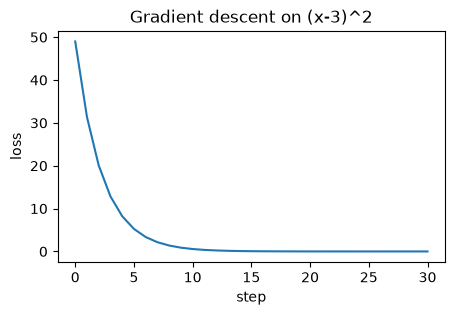

In [5]:
def loss_fn(x):
    return (x - 3) ** 2

def grad_fn(x):
    return 2 * (x - 3)     # analytic gradient of (x-3)^2

x = 10.0            # start far from the minimum at x=3
learning_rate = 0.1
history = [x]

for step in range(30):
    grad = grad_fn(x)
    x = x - learning_rate * grad
    history.append(x)

print("final x:", x, "(should be close to 3.0)")
print("loss curve (every 5 steps):", [round(loss_fn(v), 4) for v in history[::5]])

assert abs(x - 3.0) < 1e-2
losses = [loss_fn(v) for v in history]
assert all(losses[i] >= losses[i+1] - 1e-9 for i in range(len(losses) - 1))  # monotonically non-increasing

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(losses)
ax.set_xlabel("step"); ax.set_ylabel("loss"); ax.set_title("Gradient descent on (x-3)^2")
plt.show()


⚠️ **Common Mistake:** too high a learning rate overshoots and can diverge instead of
converge.

In [6]:
x_diverging = 10.0
too_high_lr = 1.1   # > 1.0 for this quadratic -> overshoots and diverges
diverge_history = [x_diverging]
for step in range(10):
    x_diverging = x_diverging - too_high_lr * grad_fn(x_diverging)
    diverge_history.append(x_diverging)

print("with too-high a learning rate, x explodes instead of converging:")
print([round(v, 2) for v in diverge_history])
assert abs(diverge_history[-1]) > abs(diverge_history[0])   # grew instead of shrinking


with too-high a learning rate, x explodes instead of converging:
[10.0, -5.4, 13.08, -9.1, 17.52, -14.42, 23.9, -22.08, 33.1, -33.12, 46.34]


## 5. Gradient descent on a small MSE loss (linear regression by hand)

💡 **Intuition:** this is literally what `07_regression`'s from-scratch linear regression on Day
2 will do — the only new piece there is fitting more than one parameter on real data.

learned w=2.036 (true=2.0), b=-1.001 (true=-1.0)
initial MSE: 3.778, final MSE: 0.085


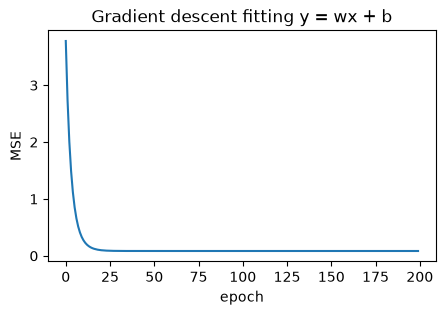

In [7]:
n = 100
X = rng.normal(size=n)
true_w, true_b = 2.0, -1.0
y = true_w * X + true_b + rng.normal(scale=0.3, size=n)   # noisy linear data

w, b = 0.0, 0.0       # start from scratch
lr = 0.1
mse_history = []

for epoch in range(200):
    y_pred = w * X + b
    error = y_pred - y
    mse = np.mean(error ** 2)
    mse_history.append(mse)

    grad_w = np.mean(2 * error * X)   # dMSE/dw
    grad_b = np.mean(2 * error)       # dMSE/db

    w -= lr * grad_w
    b -= lr * grad_b

print(f"learned w={w:.3f} (true={true_w}), b={b:.3f} (true={true_b})")
print(f"initial MSE: {mse_history[0]:.3f}, final MSE: {mse_history[-1]:.3f}")

assert abs(w - true_w) < 0.1
assert abs(b - true_b) < 0.1
assert mse_history[-1] < mse_history[0]

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(mse_history)
ax.set_xlabel("epoch"); ax.set_ylabel("MSE"); ax.set_title("Gradient descent fitting y = wx + b")
plt.show()


## 6. Connection to what's next

This is precisely `07_regression` on Day 2 (linear regression from scratch), and precisely the
mechanism behind `16_backpropagation` on Day 3 (the gradients just come from the chain rule
through many layers instead of one line of algebra). PyTorch's `autograd` (`19_pytorch_autograd`)
automates exactly the numerical-gradient-matching-analytic-gradient check performed throughout
this notebook.

## 7. Interview questions
1. Why does gradient descent subtract the gradient rather than add it?
2. What happens if the learning rate is too high, and why?
3. State the chain rule and explain its role in backpropagation in one sentence.
4. Why would you ever use a numerical gradient to check an analytic one, given analytic gradients are faster?
5. Why does mini-batch (rather than full-batch) gradient descent still work, probabilistically?

## 8. Exercises
1. Minimize `f(x) = x^4 - 3x^2 + x` from several different starting points and observe when gradient descent gets stuck in a local minimum.
2. Add momentum (`v ← βv + ∇L`, `θ ← θ - ηv`) to the quadratic gradient-descent example and compare convergence speed.
3. Extend the MSE linear-regression example to 2 input features and verify the learned weights approach the true ones.

## 9. Summary

✅ Derivative → partial derivative → gradient → chain rule → gradient descent is the complete
mechanism by which every model in this curriculum learns. This closes Day 1 — next session:
Day 2 (Machine Learning), starting from `06_ml_fundamentals`.